# Financial Behavior and Investment Patterns — Survey Analysis

This notebook analyzes the supplied Google Forms response workbook using descriptive statistics and visualizations. It removes timestamp, email, and name columns before analysis. It does not display individual rows or open-ended answers.

**Data required:** place a privacy-reviewed copy at `data/survey_responses.xlsx`, or set `SURVEY_DATA_PATH` to a local path. Do not commit the original workbook or identifying free-text responses.


In [1]:
from pathlib import Path
import os
import re
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display

DATA_PATH = Path(os.getenv("SURVEY_DATA_PATH", "data/survey_responses.xlsx"))
FIGURE_DIR = Path("results/figures")
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

if not DATA_PATH.exists():
    raise FileNotFoundError(f"Survey workbook not found: {DATA_PATH}. Add a local copy or set SURVEY_DATA_PATH.")
raw = pd.read_excel(DATA_PATH)
private_columns = [c for c in raw.columns if c.strip().lower() in {"timestamp", "email address", "full name", "name"}]
df = raw.drop(columns=private_columns, errors="ignore").copy()
del raw

def find_col(prefix, suffix=None):
    matches = [c for c in df.columns if c.strip().startswith(prefix)]
    if suffix:
        exact = next((c for c in matches if c.endswith(suffix)), None)
        if exact is not None:
            return exact
    if not matches:
        raise KeyError(f"Could not find a column beginning with {prefix!r}")
    return matches[0]

group_col = find_col("Which age group")
group = df[group_col].fillna("Missing")
youth = df[group.str.startswith("Youth", na=False)]
early = df[group.str.startswith("Early Adult", na=False)]
midlife = df[group.str.startswith("Midlife Adult", na=False)]
seniors = df[group.str.startswith("Senior", na=False)]
print(f"Rows: {len(df)}; identifying columns excluded: {len(private_columns)}")


Rows: 166; identifying columns excluded: 3


In [2]:
# Overall sample composition
summary = group.value_counts(dropna=False).rename_axis("Age group (self-selected)").to_frame("Responses")
summary["Percent"] = (summary["Responses"] / len(df) * 100).round(1)
display(summary)
display(df["Gender"].value_counts(dropna=False).rename("Responses").to_frame())


,Responses,Percent
Age group (self-selected),,
Youth (13–22),117,70.5
Midlife Adult (31–50),44,26.5
Early Adult (23–30),4,2.4
Senior (50+),1,0.6


,Responses
Gender,
Male,83
Female,83


In [3]:
def counts_for(subset, prefix, suffix=None):
    col = find_col(prefix, suffix)
    counts = subset[col].dropna().astype(str).str.strip().value_counts()
    out = counts.rename_axis("Response").to_frame("Count")
    out["Percent of answered"] = (out["Count"] / out["Count"].sum() * 100).round(1)
    return out

# Youth module: each percentage uses the question's answered count.
for label, prefix in [("Allowance", "Do you receive pocket money"),
                      ("Allowance saving", "How much of your allowance"),
                      ("Saving awareness", "Do you know about saving money"),
                      ("Investment awareness", "Have you ever heard about investments"),
                      ("Financial-planning awareness", "Do you know about financial planning")]:
    print(label)
    display(counts_for(youth, prefix))

print("Monthly allowance bands")
display(counts_for(youth, "How much do you usually receive monthly?"))
print("School financial-literacy education")
display(counts_for(youth, "Do you think financial literacy should be taught"))

# Multiple-select spending answers are counted once per selected category.
spending_col = find_col("What do you spend the most on?")
spending_tokens = youth[spending_col].dropna().astype(str).str.split(r"[,;]").explode().str.strip()
display(spending_tokens.value_counts().head(10).rename_axis("Selected category").to_frame("Selections"))


Allowance


,Count,Percent of answered
Response,,
Yes,66,56.4
No,28,23.9
Maybe,23,19.7


Allowance saving


,Count,Percent of answered
Response,,
25 - 50%,44,47.3
Less than 25%,36,38.7
more than 50%,13,14.0


Saving awareness


...

Monthly allowance bands


,Count,Percent of answered
Response,,
less than ₹500,59,50.4
₹500–₹1000,32,27.4
₹1001–₹3000,17,14.5
More than ₹3000,9,7.7


School financial-literacy education


,Count,Percent of answered
Response,,
Yes,113,96.6
No,4,3.4


,Selections
Selected category,
Food,100
Travel,63
Shopping,40
Entertainment,28
Education,24
Travelling,1
Wallet,1
For Art supplies,1


In [4]:
# Early Adult subgroup: n is small, so these are descriptive counts only.
print("Early Adult respondents:", len(early))
display(counts_for(early, "What percentage of your income do you save"))
display(counts_for(early, "Have you ever invested money"))
early_conf = pd.to_numeric(early[find_col("How confident are you in managing your own finances")], errors="coerce").dropna()
print(f"Confidence: n={len(early_conf)}, median={early_conf.median() if len(early_conf) else np.nan:.1f}/5")

print("Income bands")
display(counts_for(early, "What is your monthly income/stipend"))
print("Steady income")
display(counts_for(early, "Do you have a steady monthly income"))
print("Family financial dependence")
display(counts_for(early, "Do you depend financially"))


Early Adult respondents: 4


,Count,Percent of answered
Response,,
Less than 20%,3,75.0
31–50%,1,25.0


,Count,Percent of answered
Response,,
Yes,3,75.0
No,1,25.0


Confidence: n=4, median=4.0/5
Income bands


,Count,Percent of answered
Response,,
Less than ₹20k,2,50.0
₹50k–₹1L,1,25.0
₹20k–₹50k,1,25.0


Steady income


,Count,Percent of answered
Response,,
Yes,2,50.0
No,1,25.0
Maybe,1,25.0


Family financial dependence


,Count,Percent of answered
Response,,
Partially,2,50.0
No,1,25.0
Yes,1,25.0


In [5]:
# Midlife subgroup
print("Midlife Adult respondents:", len(midlife))
for label, prefix in [("Household financial situation", "How would you describe your household"),
                      ("Current loans", "Do you currently have loans"),
                      ("Saving or investing", "What percentage of your income do you save or invest"),
                      ("Long-term planning", "Do you actively plan for long-term")]:
    print(label)
    display(counts_for(midlife, prefix))
mgmt = pd.to_numeric(midlife[find_col("How well do you think you manage your finances")], errors="coerce").dropna()
goal_conf = pd.to_numeric(midlife[find_col("How confident are you that you are on track")], errors="coerce").dropna()
print(f"Financial management rating: n={len(mgmt)}, mean={mgmt.mean():.2f}, median={mgmt.median():.0f}/5")
print(f"Long-term-goal confidence: n={len(goal_conf)}, mean={goal_conf.mean():.2f}, median={goal_conf.median():.0f}/5")

# Split multiple-select investment holdings before counting choices.
holdings_col = find_col("What type of investments do you currently hold?")
holding_tokens = midlife[holdings_col].dropna().astype(str).str.split(r"[,;]").explode().str.strip()
display(holding_tokens.value_counts().rename_axis("Selected holding").to_frame("Selections"))


Midlife Adult respondents: 44
Household financial situation


,Count,Percent of answered
Response,,
Comfortable (able to save and invest regularly),21,47.7
Stable (able to meet expenses with limited savings),18,40.9
"Strained (struggle to meet expenses, little or no savings)",3,6.8
Dependent on loans/credit,2,4.5


Current loans


,Count,Percent of answered
Response,,
Yes,31,70.5
No,13,29.5


Saving or investing


,Count,Percent of answered
Response,,
21 - 30%,15,34.1
10 - 20%,12,27.3
Less than 10%,11,25.0
31 - 50%,4,9.1
More than 50%,2,4.5


Long-term planning


,Count,Percent of answered
Response,,
Yes,24,54.5
Sometimes,11,25.0
Regularly,6,13.6
Rarely,3,6.8


Financial management rating: n=44, mean=3.30, median=3/5
Long-term-goal confidence: n=44, mean=3.45, median=3/5


,Selections
Selected holding,
Mutual Funds,28
Insurance,24
Stocks,20
Gold,18
Real Estate,16
FD,16
Pension,4
Sip,1
Crypto,1


In [6]:
# First learned about saving/investing: numeric or parseable values only.
def age_values(subset, prefix, suffix=None, parse_text=False):
    col = find_col(prefix, suffix)
    s = subset[col].astype("string")
    if parse_text:
        s = s.str.extract(r"(\d{1,2}(?:\.\d+)?)", expand=False)
    return pd.to_numeric(s, errors="coerce").dropna()

learned = {
    "Youth": age_values(youth, "If yes, at what age"),
    "Early Adult": age_values(early, "At what age did you first learn about saving and investing?"),
    "Midlife Adult": age_values(midlife, "At what age did you first learn about saving and investing?", ".1", True),
    "Senior": age_values(seniors, "At what age did you first learn about saving and investing?", ".2"),
}
learned_summary = pd.DataFrame([{"Group": name, "Group n": len(sub), "Numeric answers": len(values),
                                 "Median age": values.median() if len(values) else np.nan,
                                 "Range": f"{values.min():.0f}–{values.max():.0f}" if len(values) else "—"}
                                for (name, sub), values in zip([("Youth", youth), ("Early Adult", early), ("Midlife Adult", midlife), ("Senior", seniors)], learned.values())])
display(learned_summary)


,Group,Group n,Numeric answers,Median age,Range
0,Youth,117,57,15.0,6–19
1,Early Adult,4,4,18.5,16–23
2,Midlife Adult,44,44,26.0,15–43
3,Senior,1,1,28.0,28–28


In [7]:
# Ordered categories and ratings are shown as counts. This is descriptive; no causal or significance claim.
saving_col = find_col("What percentage of your income do you save or invest")
confidence_col = find_col("How confident are you that you are on track")
display(pd.crosstab(midlife[saving_col], midlife[confidence_col], dropna=False, margins=True))


How confident are you that you are on track to achieve your long-term financial goals?,1.0,2.0,3.0,4.0,5.0,All
What percentage of your income do you save or invest?,,,,,,
10 - 20%,2,2,2,4,2,12
21 - 30%,1,0,8,1,5,15
31 - 50%,0,0,0,1,3,4
Less than 10%,1,3,4,2,1,11
More than 50%,0,0,0,1,1,2
All,4,5,14,9,12,44


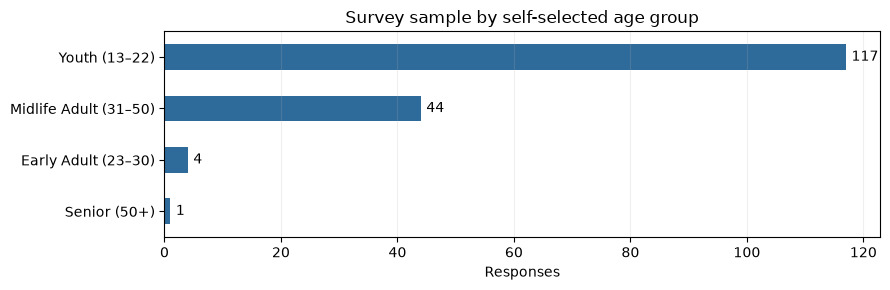

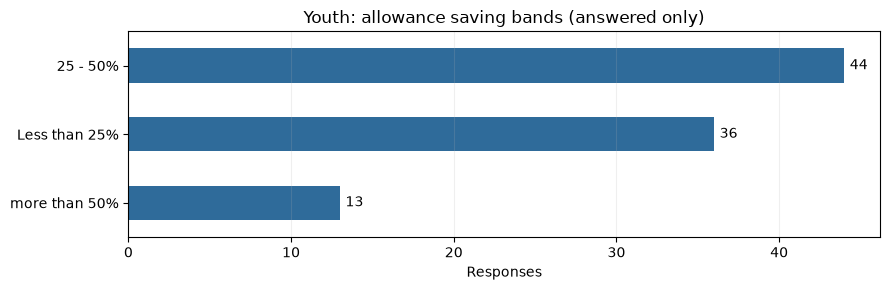

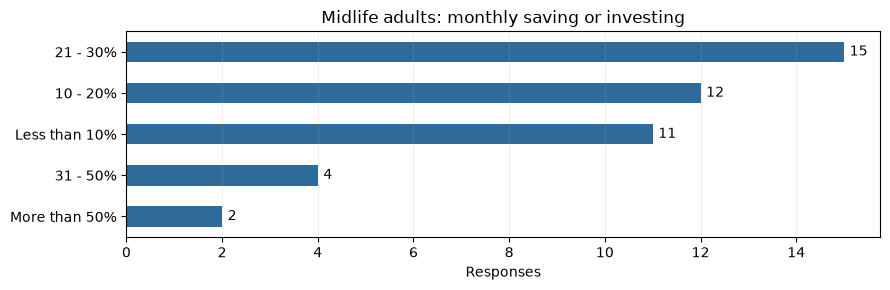

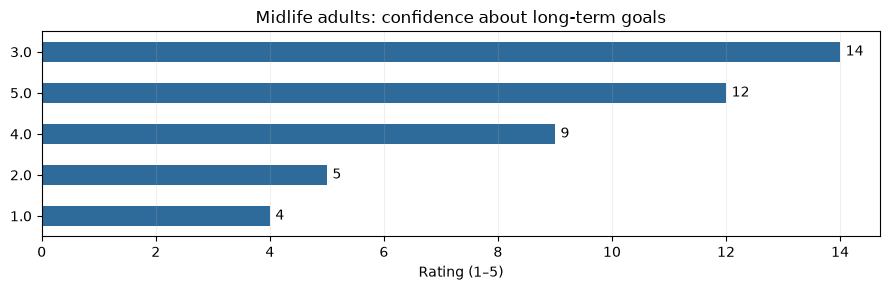

In [8]:
# Create reproducible charts. Each chart labels the valid-response denominator.
def bar_chart(counts, title, xlabel, filename):
    counts = counts.sort_values(ascending=False)
    ax = counts.plot(kind="barh", color="#2F6B9A", figsize=(9, max(3, 0.48 * len(counts))))
    ax.invert_yaxis()
    ax.set_title(title)
    ax.set_xlabel(xlabel)
    ax.set_ylabel("")
    ax.grid(axis="x", alpha=0.2)
    for container in ax.containers:
        ax.bar_label(container, padding=4)
    plt.tight_layout()
    plt.savefig(FIGURE_DIR / filename, dpi=160, bbox_inches="tight")
    plt.show()

bar_chart(group.value_counts(), "Survey sample by self-selected age group", "Responses", "age_group_sample_sizes.png")
bar_chart(youth[find_col("How much of your allowance")].dropna().astype(str).value_counts(),
          "Youth: allowance saving bands (answered only)", "Responses", "youth_allowance_savings.png")
bar_chart(midlife[saving_col].dropna().astype(str).value_counts(),
          "Midlife adults: monthly saving or investing", "Responses", "midlife_saving_bands.png")
bar_chart(goal_conf.value_counts().sort_index(),
          "Midlife adults: confidence about long-term goals", "Rating (1–5)", "midlife_goal_confidence.png")


## Interpretation notes

- The workbook has 166 responses: Youth 117, Midlife Adult 44, Early Adult 4, Senior 1. The two smallest groups are too small for reliable group comparisons.
- Age groups are self-selected and the workbook's Midlife 31–50 and Senior 50+ labels overlap at age 50.
- Awareness and confidence are self-reported; the questionnaire does not establish an objective financial-literacy score.
- Saving responses are bands, not exact percentages. Do not treat their labels as exact numeric rates without stating an assumption.
- Blank group-specific fields often mean the question was not shown to that respondent. Always use the answered count for the particular question.
- The study is cross-sectional, so it cannot establish causation. Open-ended answers are omitted from outputs and should be privacy-reviewed before sharing.
